# EA3 — Comparación de datos climáticos: Medellín y Quito

**Estudiante:** Esteban Duarte Salgado*  
**Curso:** PREICA2602B020125  
**Periodo analizado:** 1 de enero a 31 de diciembre de 2024 (366 días)  
**Ciudades:** Medellín, Colombia y Quito, Ecuador.

## Pregunta y predicción

**Pregunta guía:** ¿Qué similitudes y diferencias se observan en las variables climáticas de Medellín y Quito durante el mismo periodo?

**Predicción previa:** espero que Medellín presente temperaturas máximas diarias mayores por su menor altitud, mientras que Quito tenga temperaturas más bajas. Espero que la precipitación acumulada difiera entre ciudades y que ambas tengan varios días con lluvia. Esta es una expectativa que se verificará con los datos, no una conclusión anticipada.

> **Alcance de los datos:** se usa ERA5, un conjunto de reanálisis meteorológico. Sus valores son estimaciones históricas derivadas de observaciones y modelos, interpoladas a una cuadrícula; no son lecturas directas de una estación puntual. Por eso, las conclusiones describen estas series de cuadrícula para los puntos cercanos a las ciudades, no todas las condiciones de cada ciudad.

## 1. Fuentes y comparabilidad

Las dos tablas se consultan en **Open-Meteo Historical Weather API**, solicitando el modelo ERA5 y los mismos campos para las coordenadas de cada ciudad. La frecuencia es diaria y el intervalo solicitado es idéntico.

| Ciudad | País | Coordenadas solicitadas | Variables usadas | Unidades |
|---|---|---:|---|---|
| Medellín | Colombia | 6.2442, -75.5812 | temperatura media diaria, temperatura máxima diaria, precipitación diaria | °C, °C, mm |
| Quito | Ecuador | -0.1807, -78.4678 | temperatura media diaria, temperatura máxima diaria, precipitación diaria | °C, °C, mm |

**Periodo:** 2024-01-01 a 2024-12-31. **Frecuencia:** un registro por día. No se convierten unidades porque ambas respuestas ya están en °C y mm. Se usa `temperature_2m_max` para las gráficas y medidas de temperatura, y `precipitation_sum` para lluvia.

- Documentación del archivo histórico y variables: [Open-Meteo Historical Weather API](https://open-meteo.com/en/docs/historical-weather-api)
- Medellín: [respuesta de la API con ERA5](https://archive-api.open-meteo.com/v1/archive?latitude=6.2442&longitude=-75.5812&start_date=2024-01-01&end_date=2024-12-31&daily=temperature_2m_mean%2Ctemperature_2m_max%2Cprecipitation_sum&timezone=America%2FBogota&models=era5)
- Quito: [respuesta de la API con ERA5](https://archive-api.open-meteo.com/v1/archive?latitude=-0.1807&longitude=-78.4678&start_date=2024-01-01&end_date=2024-12-31&daily=temperature_2m_mean%2Ctemperature_2m_max%2Cprecipitation_sum&timezone=America%2FGuayaquil&models=era5)

**Archivos entregados:** `datos/medellin.csv` y `datos/quito.csv`. Las tablas se guardan para que el análisis pueda ejecutarse sin conexión; la celda siguiente también permite volver a descargarlas si los archivos no están presentes.

In [1]:
from pathlib import Path
from urllib.request import urlopen
from urllib.parse import urlencode
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

DATA_DIR = Path("datos")
DATA_DIR.mkdir(exist_ok=True)
START_DATE = "2024-01-01"
END_DATE = "2024-12-31"

CITY_CONFIG = {
    "Medellín": {
        "filename": "medellin.csv", "latitude": 6.2442,
        "longitude": -75.5812, "timezone": "America/Bogota"
    },
    "Quito": {
        "filename": "quito.csv", "latitude": -0.1807,
        "longitude": -78.4678, "timezone": "America/Guayaquil"
    },
}

# Si faltara un CSV, se consulta la misma API, modelo, periodo y variables.
for city, config in CITY_CONFIG.items():
    file_path = DATA_DIR / config["filename"]
    if not file_path.exists():
        params = {
            "latitude": config["latitude"],
            "longitude": config["longitude"],
            "start_date": START_DATE,
            "end_date": END_DATE,
            "daily": "temperature_2m_mean,temperature_2m_max,precipitation_sum",
            "timezone": config["timezone"],
            "models": "era5",
        }
        request_url = "https://archive-api.open-meteo.com/v1/archive?" + urlencode(params)
        with urlopen(request_url, timeout=60) as response:
            payload = json.load(response)
        if payload.get("error"):
            raise RuntimeError(f"Error descargando {city}: {payload.get('reason')}")
        daily = payload["daily"]
        downloaded = pd.DataFrame({
            "date": daily["time"],
            "temperature_mean_c": daily["temperature_2m_mean"],
            "temperature_max_c": daily["temperature_2m_max"],
            "precipitation_mm": daily["precipitation_sum"],
        })
        downloaded.to_csv(file_path, index=False)

print("Archivos listos:", [str(DATA_DIR / x["filename"]) for x in CITY_CONFIG.values()])

ModuleNotFoundError: No module named 'numpy'

## 2. Carga y revisión inicial

Se convierten explícitamente las fechas a `datetime` y las mediciones a números. Primero se inspeccionan las columnas, las primeras filas, el tamaño, el rango temporal, los faltantes y las fechas repetidas. Un faltante permanece como faltante: no se interpreta como cero.

In [ ]:
medellin_raw = pd.read_csv(DATA_DIR / "medellin.csv")
quito_raw = pd.read_csv(DATA_DIR / "quito.csv")

for df in (medellin_raw, quito_raw):
    df["date"] = pd.to_datetime(df["date"], errors="coerce")
    for column in ["temperature_mean_c", "temperature_max_c", "precipitation_mm"]:
        df[column] = pd.to_numeric(df[column], errors="coerce")

for city, df in [("Medellín", medellin_raw), ("Quito", quito_raw)]:
    print(f"\n{city}")
    print("Columnas:", df.columns.tolist())
    print("Dimensiones:", df.shape)
    print("Fechas:", df["date"].min().date(), "a", df["date"].max().date())
    print("Faltantes por columna:\n", df.isna().sum())
    print("Fechas duplicadas:", int(df["date"].duplicated().sum()))
    display(df.head())


Medellín
Columnas: ['date', 'temperature_mean_c', 'temperature_max_c', 'precipitation_mm']
Dimensiones: (366, 4)
Fechas: 2024-01-01 a 2024-12-31
Faltantes por columna:
 date                  0
temperature_mean_c    0
temperature_max_c     0
precipitation_mm      0
dtype: int64
Fechas duplicadas: 0

Quito
Columnas: ['date', 'temperature_mean_c', 'temperature_max_c', 'precipitation_mm']
Dimensiones: (366, 4)
Fechas: 2024-01-01 a 2024-12-31
Faltantes por columna:
 date                  0
temperature_mean_c    0
temperature_max_c     0
precipitation_mm      0
dtype: int64
Fechas duplicadas: 0


,date,temperature_mean_c,temperature_max_c,precipitation_mm
0,2024-01-01,22.1,27.6,1.4
1,2024-01-02,22.7,28.5,4.0
2,2024-01-03,22.7,28.9,1.0
3,2024-01-04,22.3,29.4,0.6
4,2024-01-05,21.9,27.8,0.2


,date,temperature_mean_c,temperature_max_c,precipitation_mm
0,2024-01-01,13.2,17.3,7.3
1,2024-01-02,12.7,15.9,9.4
2,2024-01-03,13.4,17.0,15.6
3,2024-01-04,13.3,16.7,32.2
4,2024-01-05,13.8,17.3,7.8


## 3. Fechas comunes y datos válidos

Se alinean las tablas por fecha y se conservan solamente las fechas presentes en ambas. Luego se excluye una fila de los cálculos que requiera alguna variable faltante. La comparación no desplaza ni recorta el periodo de una ciudad para empatarlo con la otra.

In [ ]:
required = ["temperature_mean_c", "temperature_max_c", "precipitation_mm"]
medellin = medellin_raw[["date"] + required].rename(
    columns={column: f"medellin_{column}" for column in required}
)
quito = quito_raw[["date"] + required].rename(
    columns={column: f"quito_{column}" for column in required}
)

aligned = medellin.merge(quito, on="date", how="inner", validate="one_to_one").sort_values("date")
expected_dates = pd.date_range(START_DATE, END_DATE, freq="D")
common_dates = pd.DatetimeIndex(aligned["date"])
valid_rows = aligned.dropna().copy()

print("Filas Medellín:", len(medellin_raw), "| Filas Quito:", len(quito_raw))
print("Fechas comunes:", len(aligned))
print("Filas completas para todas las variables:", len(valid_rows))
print("Fechas esperadas en el año:", len(expected_dates))
print("¿Cada fecha del periodo está en ambas tablas?:", common_dates.equals(expected_dates))
print("Faltantes después de alinear:\n", aligned.isna().sum())

if aligned["date"].duplicated().any():
    raise ValueError("Hay fechas duplicadas: revisar antes de comparar.")
if not common_dates.equals(expected_dates):
    print("Nota: el periodo solicitado es el mismo, pero hay fechas ausentes; se usarán las fechas válidas comunes.")
if valid_rows.empty:
    raise ValueError("No hay filas completas disponibles para el análisis.")

Filas Medellín: 366 | Filas Quito: 366
Fechas comunes: 366
Filas completas para todas las variables: 366
Fechas esperadas en el año: 366
¿Cada fecha del periodo está en ambas tablas?: True
Faltantes después de alinear:
 date                           0
medellin_temperature_mean_c    0
medellin_temperature_max_c     0
medellin_precipitation_mm      0
quito_temperature_mean_c       0
quito_temperature_max_c        0
quito_precipitation_mm         0
dtype: int64


## 4. Arrays NumPy, cortes, máscaras y resumen

Los arrays mantienen el orden cronológico de las fechas alineadas. El corte de siete días permite inspeccionar una semana. La máscara de lluvia identifica precipitación estrictamente mayor que 0 mm; la máscara de temperatura usa el mismo umbral de **25 °C** para las dos ciudades. Las filas con faltantes se excluyeron antes de construir los arrays, sin sustituir valores.

In [ ]:
dates = valid_rows["date"].to_numpy()
temp_max = valid_rows[["medellin_temperature_max_c", "quito_temperature_max_c"]].to_numpy(dtype=float)
temp_mean = valid_rows[["medellin_temperature_mean_c", "quito_temperature_mean_c"]].to_numpy(dtype=float)
precip = valid_rows[["medellin_precipitation_mm", "quito_precipitation_mm"]].to_numpy(dtype=float)
city_names = np.array(["Medellín", "Quito"])

print("Forma del array de temperatura máxima (días, ciudades):", temp_max.shape)
print("Primeros 7 días — fecha, máxima Medellín, máxima Quito:\n", np.column_stack((dates[:7].astype(str), temp_max[:7])))

RAIN_THRESHOLD_MM = 0.0
HOT_THRESHOLD_C = 25.0
rainy_mask = precip > RAIN_THRESHOLD_MM
hot_mask = temp_max > HOT_THRESHOLD_C

summary_rows = []
for city_index, city in enumerate(city_names):
    city_tmax = temp_max[:, city_index]
    city_rain = precip[:, city_index]
    summary_rows.append({
        "Ciudad": city,
        "Promedio temp. máxima (°C)": np.mean(city_tmax),
        "Mínimo temp. máxima (°C)": np.min(city_tmax),
        "Máximo temp. máxima (°C)": np.max(city_tmax),
        "Precipitación total (mm)": np.sum(city_rain),
        "Días lluviosos (> 0 mm)": int(np.sum(rainy_mask[:, city_index])),
        "Días con máxima > 25 °C": int(np.sum(hot_mask[:, city_index])),
    })
summary = pd.DataFrame(summary_rows).set_index("Ciudad")
display(summary.round(2))

Forma del array de temperatura máxima (días, ciudades): (366, 2)
Primeros 7 días — fecha, máxima Medellín, máxima Quito:
 [['2024-01-01T00:00:00.000000000' '27.6' '17.3']
 ['2024-01-02T00:00:00.000000000' '28.5' '15.9']
 ['2024-01-03T00:00:00.000000000' '28.9' '17.0']
 ['2024-01-04T00:00:00.000000000' '29.4' '16.7']
 ['2024-01-05T00:00:00.000000000' '27.8' '17.3']
 ['2024-01-06T00:00:00.000000000' '28.3' '17.5']
 ['2024-01-07T00:00:00.000000000' '28.4' '17.8']]


,Promedio temp. máxima (°C),Mínimo temp. máxima (°C),Máximo temp. máxima (°C),Precipitación total (mm),Días lluviosos (> 0 mm),Días con máxima > 25 °C
Ciudad,,,,,,
Medellín,27.64,20.9,32.2,2482.3,342,317
Quito,17.73,13.8,22.0,2929.8,363,0


### Broadcasting

Se resta a cada máxima diaria el promedio anual de su ciudad. `temp_max` tiene forma `(n_días, 2)` y `annual_mean_by_city[None, :]` tiene forma `(1, 2)`. NumPy expande esta última fila a todos los días por *broadcasting*. El resultado indica cuánto estuvo cada día por encima o por debajo del promedio anual de su ciudad.

In [ ]:
annual_mean_by_city = np.mean(temp_max, axis=0)
daily_anomaly = temp_max - annual_mean_by_city[None, :]
print("Forma de las medias anuales:", annual_mean_by_city[None, :].shape)
print("Forma del resultado de broadcasting:", daily_anomaly.shape)
print("Anomalías de los primeros 5 días (°C):\n", np.round(daily_anomaly[:5], 2))

Forma de las medias anuales: (1, 2)
Forma del resultado de broadcasting: (366, 2)
Anomalías de los primeros 5 días (°C):
 [[-0.04 -0.43]
 [ 0.86 -1.83]
 [ 1.26 -0.73]
 [ 1.76 -1.03]
 [ 0.16 -0.43]]


## 5. Agregación mensual

Para temperatura se calcula el promedio de las máximas diarias de cada mes. Para precipitación se suman los valores diarios de cada mes. Se conserva el mismo calendario mensual para las dos ciudades.

In [ ]:
monthly = valid_rows.copy()
monthly["month"] = monthly["date"].dt.month
monthly_temp = monthly.groupby("month")[["medellin_temperature_max_c", "quito_temperature_max_c"]].mean()
monthly_rain = monthly.groupby("month")[["medellin_precipitation_mm", "quito_precipitation_mm"]].sum()
month_names = ["Ene", "Feb", "Mar", "Abr", "May", "Jun", "Jul", "Ago", "Sep", "Oct", "Nov", "Dic"]
monthly_temp.index = month_names
monthly_rain.index = month_names

display(monthly_temp.round(2).rename(columns={
    "medellin_temperature_max_c": "Medellín (°C)",
    "quito_temperature_max_c": "Quito (°C)"
}))
display(monthly_rain.round(1).rename(columns={
    "medellin_precipitation_mm": "Medellín (mm)",
    "quito_precipitation_mm": "Quito (mm)"
}))

,Medellín (°C),Quito (°C)
Ene,29.20,17.77
Feb,28.10,17.68
Mar,28.72,17.66
Abr,27.34,17.62
May,27.51,18.24
Jun,27.27,17.52
Jul,28.61,18.46
Ago,28.37,18.19
Sep,29.19,18.40
Oct,27.17,18.13


,Medellín (mm),Quito (mm)
Ene,26.2,210.7
Feb,102.3,307.5
Mar,106.4,288.4
Abr,399.3,377.5
May,326.5,307.6
Jun,287.9,252.1
Jul,117.6,89.2
Ago,162.6,115.7
Sep,118.9,82.4
Oct,300.2,263.3


## 6. Gráfica 1 — temperatura máxima mensual

La gráfica muestra el promedio mensual de las máximas diarias. Así se comparan ambas ciudades mes a mes, aunque la agregación oculta los cambios de un día a otro.

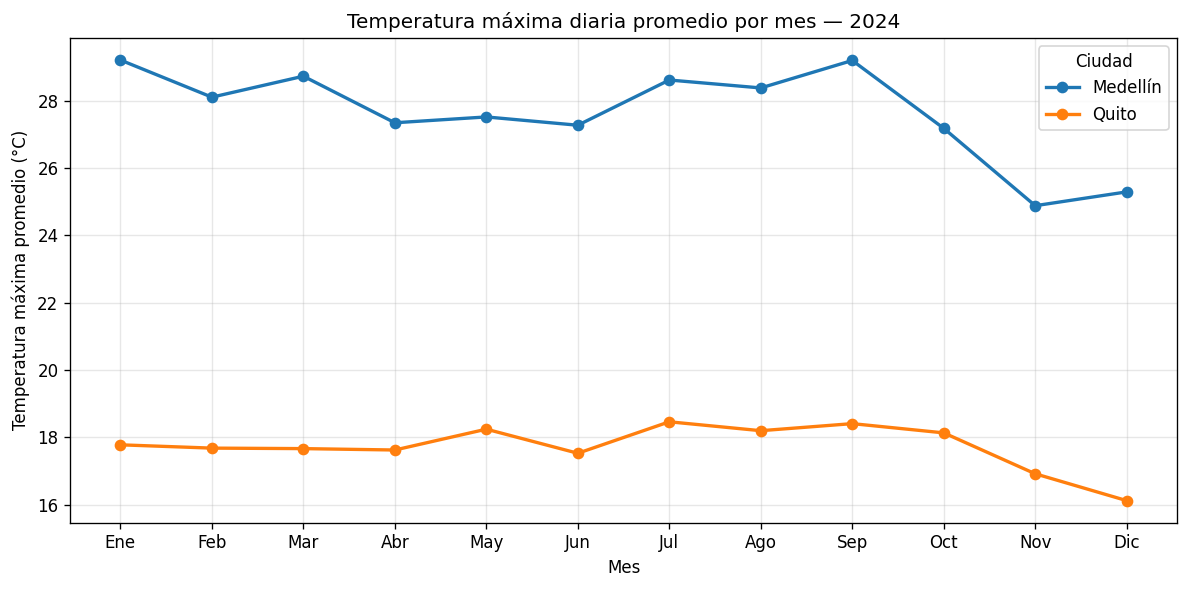

In [ ]:
fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(month_names, monthly_temp["medellin_temperature_max_c"], marker="o", linewidth=2, label="Medellín")
ax.plot(month_names, monthly_temp["quito_temperature_max_c"], marker="o", linewidth=2, label="Quito")
ax.set_title("Temperatura máxima diaria promedio por mes — 2024")
ax.set_xlabel("Mes")
ax.set_ylabel("Temperatura máxima promedio (°C)")
ax.grid(True, alpha=0.3)
ax.legend(title="Ciudad")
fig.tight_layout()
plt.show()

**Qué se observa:** Medellín tuvo máximas mensuales promedio superiores a Quito durante todos los meses; por ejemplo, en enero fueron aproximadamente **29,2 °C** y **17,8 °C**, respectivamente. Quito mostró una variación mensual más estrecha en esta serie. **Qué no permite concluir:** el promedio mensual no describe cada día ni explica por qué existe la diferencia; tampoco equivale a comparar lecturas tomadas en dos estaciones idénticas.

## 7. Gráfica 2 — precipitación acumulada mensual

Cada barra representa la suma de la precipitación diaria del mes en milímetros. Los dos colores permiten comparar acumulados dentro de cada mes.

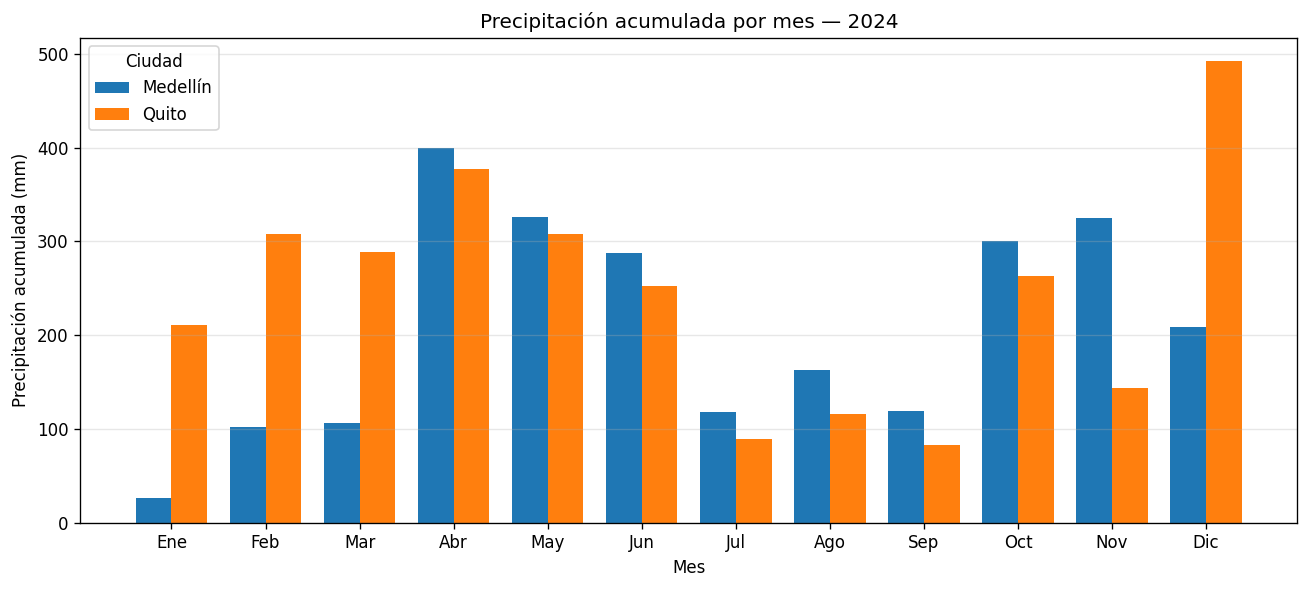

In [ ]:
x = np.arange(len(month_names))
bar_width = 0.38
fig, ax = plt.subplots(figsize=(11, 5))
ax.bar(x - bar_width / 2, monthly_rain["medellin_precipitation_mm"], bar_width, label="Medellín")
ax.bar(x + bar_width / 2, monthly_rain["quito_precipitation_mm"], bar_width, label="Quito")
ax.set_title("Precipitación acumulada por mes — 2024")
ax.set_xlabel("Mes")
ax.set_ylabel("Precipitación acumulada (mm)")
ax.set_xticks(x, month_names)
ax.legend(title="Ciudad")
ax.grid(axis="y", alpha=0.3)
fig.tight_layout()
plt.show()

**Qué se observa:** el acumulado anual fue mayor en Quito (**2.929,8 mm**) que en Medellín (**2.482,3 mm**). Quito tuvo su mayor acumulado mensual en diciembre (**492,3 mm**); Medellín, en abril (**399,3 mm**). **Qué no permite concluir:** el acumulado mensual no indica la intensidad de cada evento ni su distribución dentro del mes; tampoco prueba una tendencia climática de largo plazo a partir de un solo año.

## 8. Gráfica 3 — distribución de máximas diarias

Los histogramas comparan cuántos días caen en distintos intervalos de temperatura máxima. Se usan los mismos bins para ambas ciudades.

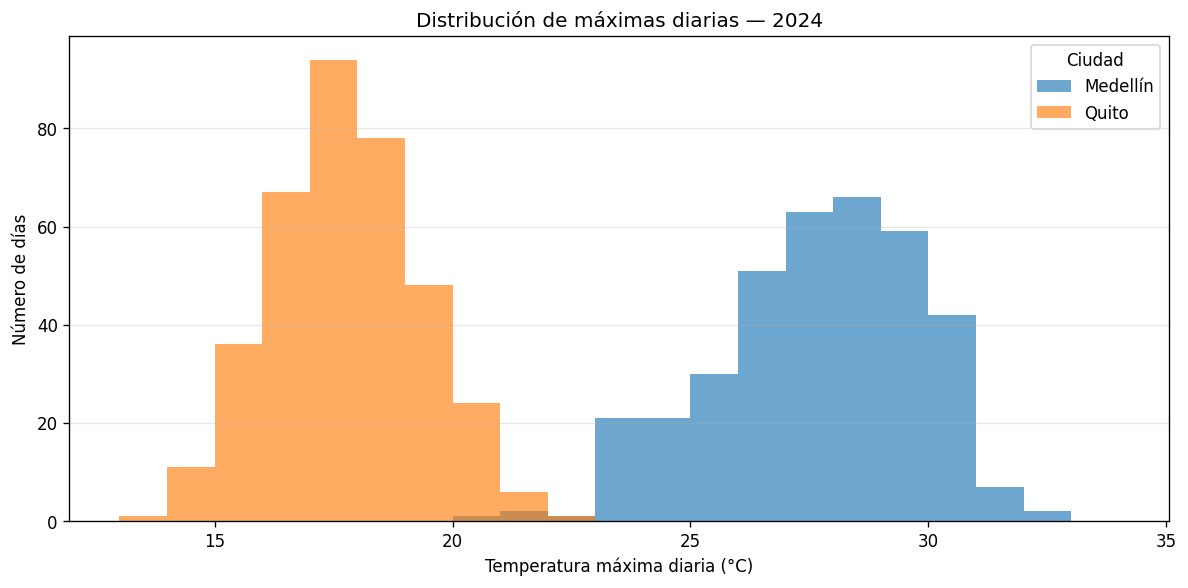

In [ ]:
combined_min = np.floor(np.min(temp_max))
combined_max = np.ceil(np.max(temp_max))
bins = np.arange(combined_min, combined_max + 1.5, 1.0)
fig, ax = plt.subplots(figsize=(10, 5))
ax.hist(temp_max[:, 0], bins=bins, alpha=0.65, label="Medellín")
ax.hist(temp_max[:, 1], bins=bins, alpha=0.65, label="Quito")
ax.set_title("Distribución de máximas diarias — 2024")
ax.set_xlabel("Temperatura máxima diaria (°C)")
ax.set_ylabel("Número de días")
ax.legend(title="Ciudad")
ax.grid(axis="y", alpha=0.3)
fig.tight_layout()
plt.show()

**Qué se observa:** las distribuciones aparecen separadas: el promedio anual de la máxima diaria fue **27,64 °C** en Medellín y **17,73 °C** en Quito; con el umbral común de 25 °C hubo **317 días** por encima del umbral en Medellín y **0** en Quito. **Qué no permite concluir:** el histograma pierde el orden temporal, no representa temperaturas mínimas ni permite atribuir la diferencia a una causa específica.

## 9. Interpretación y respuesta a la pregunta guía

1. **Diferencia de temperatura:** Medellín presentó una temperatura máxima diaria promedio anual de **27,64 °C** (mínimo diario observado en la serie: **20,9 °C**; máximo: **32,2 °C**), mientras Quito registró **17,73 °C** (mínimo: **13,8 °C**; máximo: **22,0 °C**). El mismo umbral de 25 °C se superó **317 días** en Medellín y **ningún día** en Quito.
2. **Diferencia de precipitación y similitud en días lluviosos:** Quito acumuló **2.929,8 mm**, unos **447,5 mm** más que Medellín (**2.482,3 mm**). Sin embargo, ambas series muestran lluvia en gran parte del año: **363 días** en Quito y **342 días** en Medellín con precipitación mayor que 0 mm. Esto constituye una similitud de frecuencia, junto con una diferencia en acumulado.

### Efecto del periodo y de los faltantes

Las dos consultas usan el mismo periodo, del 1 de enero al 31 de diciembre de 2024, y la misma frecuencia diaria. El año tiene 366 días. El resultado de la revisión indica cuántas fechas comunes y completas se analizaron; si hubo faltantes, las estadísticas se basan en las filas completas comunes y pueden no representar todos los días. No se reemplazaron faltantes por cero. Los ceros de precipitación se conservan como días sin precipitación reportada por la serie.

### Limitaciones

Es un solo año y los valores provienen de reanálisis ERA5 en cuadrículas cercanas a las coordenadas, no de una pareja de estaciones meteorológicas con la misma ubicación, elevación, instrumentos y protocolo. El resultado permite una comparación descriptiva de estas series, pero no generalizar a todos los años ni afirmar causalidad. Para estudiar clima de largo plazo se necesitarían muchos años y, para comparar observaciones puntuales, datos de estaciones con calidad y cobertura documentadas.

## 10. Lista de verificación de entrega

- [x] Medellín y una ciudad de otro país (Quito, Ecuador).
- [x] Mismo periodo solicitado y frecuencia diaria; se valida en el código.
- [x] Fuentes, variables, unidades y limitaciones documentadas.
- [x] Revisión de columnas, filas, tipos, faltantes, fechas y duplicados.
- [x] Arrays NumPy, cortes, máscaras booleanas y *broadcasting*.
- [x] Tres gráficas comparativas con títulos, ejes, unidades y leyendas.
- [x] Hallazgos sustentados y límites de interpretación explicados.

